In [33]:
import argparse
import lzma
import os
import pickle
import sys
from typing import Optional
import urllib.request

import numpy as np
import numpy.typing as npt

import sklearn.datasets
import sklearn.linear_model
import sklearn.metrics
import sklearn.model_selection

In [52]:
parser = argparse.ArgumentParser()
# These arguments will be set appropriately by ReCodEx, even if you change them.
parser.add_argument(
    "--predict", default=None, type=str, help="Path to the dataset to predict"
)
parser.add_argument(
    "--recodex", default=False, action="store_true", help="Running in ReCodEx"
)
parser.add_argument("--seed", default=42, type=int, help="Random seed")
# For these and any other arguments you add, ReCodEx will keep your default value.
parser.add_argument(
    "--model_path", default="rental_competition.model", type=str, help="Model path"
)

parser.add_argument(
    "--plot",
    default=True,
    const=True,
    nargs="?",
    type=str,
    help="Plot the predictions",
)

parser.add_argument(
    "--test_size",
    default=0.2,
    type=lambda x: int(x) if x.isdigit() else float(x),
    help="Test size",
)

_StoreAction(option_strings=['--test_size'], dest='test_size', nargs=None, const=None, default=0.2, type=<function <lambda> at 0x121debc10>, choices=None, required=False, help='Test size', metavar=None, deprecated=False)

In [53]:
class Dataset:
    """Rental Dataset.

    The dataset instances consist of the following 12 features:
    - season (1: winter, 2: spring, 3: summer, 4: autumn)
    - year (0: 2011, 1: 2012)
    - month (1-12)
    - hour (0-23)
    - holiday (binary indicator)
    - day of week (0: Sun, 1: Mon, ..., 6: Sat)
    - working day (binary indicator; a day is neither weekend nor holiday)
    - weather (1: clear, 2: mist, 3: light rain, 4: heavy rain)
    - temperature (normalized so that -8 Celsius is 0 and 39 Celsius is 1)
    - feeling temperature (normalized so that -16 Celsius is 0 and 50 Celsius is 1)
    - relative humidity (0-1 range)
    - windspeed (normalized to 0-1 range)

    The target variable is the number of rented bikes in the given hour.
    """

    def __init__(
        self,
        name="rental_competition.train.npz",
        url="https://ufal.mff.cuni.cz/~courses/npfl129/2425/datasets/",
    ):
        if not os.path.exists(name):
            print("Downloading dataset {}...".format(name), file=sys.stderr)
            urllib.request.urlretrieve(url + name, filename="{}.tmp".format(name))
            os.rename("{}.tmp".format(name), name)

        # Load the dataset and return the data and targets.
        dataset = np.load(name)
        for key, value in dataset.items():
            setattr(self, key, value)

In [54]:
def split_cat_num_features(X: np.ndarray) -> tuple[list[int], list[int]]:
    cat_cols = []
    num_cols = []
    for i in range(X.shape[1]):
        col = X[:, i]
        if bool(np.all(col == col.astype(int))):
            cat_cols.append(i)
        else:
            num_cols.append(i)

    return cat_cols, num_cols

In [63]:
def create_model_from_hyperparameters(
    hyperparams: dict[str, float],
) -> sklearn.pipeline.Pipeline:
    enc = sklearn.preprocessing.OneHotEncoder(
        sparse_output=False, handle_unknown="ignore"
    )
    scaler = sklearn.preprocessing.StandardScaler()
    ct = sklearn.compose.ColumnTransformer(
        [
            ("categorical", enc, hyperparams["cat_cols"]),
            ("numerical", scaler, hyperparams["num_cols"]),
        ]
    )
    poly = sklearn.preprocessing.PolynomialFeatures(2, include_bias=False)

    model = sklearn.pipeline.Pipeline(
        [
            ("col_transform", ct),
            ("poly", poly),
            ("lin reg", sklearn.linear_model.Ridge(alpha=hyperparams["lambda"])),
        ]
    )

    return model

In [64]:
def determine_best_lambda(X_train, y_train, hyperparams, plot=False) -> tuple[float]:
    lambdas = np.geomspace(0.01, 10, num=50)
    best_lambda = None
    best_rmse = float("inf")
    rmses = []

    hyperp = hyperparams.copy()

    cv = sklearn.model_selection.KFold(n_splits=5, shuffle=True, random_state=42)

    for lambda_ in lambdas:
        hyperp["lambda"] = lambda_
        model = create_model_from_hyperparameters(hyperp)

        model.fit(X_train, y_train)
        y_pred = model.predict(X_train)

        # neg_root_mean_squared_error - higher rmse is worse result
        # this splits data into 5 parts, on the 4 training happens and the fifth is used for testing
        scores = sklearn.model_selection.cross_val_score(
            model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error"
        )
        rmse = -scores.mean()
        rmses.append(rmse)

        if best_rmse > rmse:
            best_rmse = rmse
            best_lambda = lambda_

    if plot:
        import matplotlib.pyplot as plt

        plt.plot(lambdas, rmses)
        plt.xscale("log")
        plt.xlabel("L2 regularization strength $\\lambda$")
        plt.ylabel("RMSE")
        plt.show() if plot is True else plt.savefig(
            plot, transparent=True, bbox_inches="tight"
        )

    return best_lambda

In [65]:
def main(args: argparse.Namespace) -> Optional[npt.ArrayLike]:
    if args.predict is None:
        # We are training a model.
        np.random.seed(args.seed)
        dataset = Dataset()

        print(f"Dataset size: {len(dataset.data)}")

        X_train, X_test, y_train, y_test = sklearn.model_selection.train_test_split(
            dataset.data,
            dataset.target,
            test_size=args.test_size,
            random_state=args.seed,
        )

        hyperparams = dict()

        cat_cols, num_cols = split_cat_num_features(X_train)
        hyperparams["cat_cols"] = cat_cols
        hyperparams["num_cols"] = num_cols

        best_lambda = determine_best_lambda(
            X_train, y_train, hyperparams, plot=args.plot
        )
        hyperparams["lambda"] = best_lambda

        model = create_model_from_hyperparameters(hyperparams)
        model.fit(X_train, y_train)
        y_pred = model.predict(X_train)
        best_rmse = sklearn.metrics.root_mean_squared_error(y_train, y_pred)

        print(f"Best lambda: {best_lambda}, RMSE: {best_rmse}")

        y_pred = model.predict(X_test)
        rmse = sklearn.metrics.root_mean_squared_error(y_test, y_pred)
        print(f"RMSE: {rmse}")

        # Serialize the model.
        with lzma.open(args.model_path, "wb") as model_file:
            pickle.dump(model, model_file)

    else:
        # Use the model and return test set predictions, either as a Python list or a NumPy array.
        test = Dataset(args.predict)

        with lzma.open(args.model_path, "rb") as model_file:
            model = pickle.load(model_file)

        # TODO: Generate `predictions` with the test set predictions.
        predictions = model.predict(test.data)

        return predictions


Dataset size: 1000


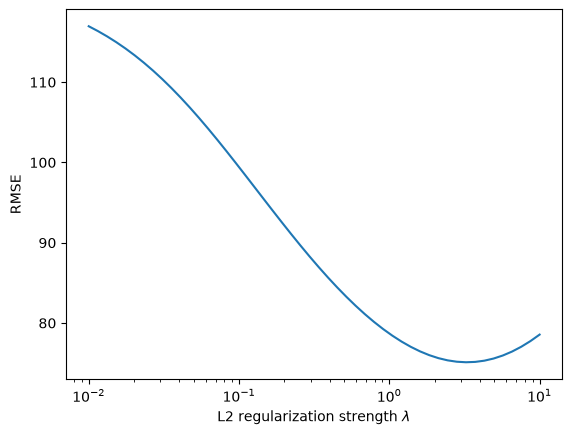

Best lambda: 3.2374575428176433, RMSE: 29.915344496841062
RMSE: 58.969271041164376


In [66]:
if __name__ == "__main__":
    main_args = parser.parse_args([] if "__file__" not in globals() else None)
    main(main_args)

# Data exploration

In [17]:
import pandas as pd

dataset = Dataset()
feature_names = ["season", "year", "month", "hour", "holiday", "weekday",
                 "workingday", "weather", "temp", "atemp", "humidity", "windspeed"]
df = pd.DataFrame(dataset.data, columns=feature_names)
df["target"] = dataset.target
df.head()

,season,year,month,hour,holiday,weekday,workingday,weather,temp,atemp,humidity,windspeed,target
0,3.0,1.0,6.0,19.0,0.0,6.0,0.0,1.0,0.80,0.6970,0.27,0.1940,425.0
1,1.0,1.0,1.0,20.0,1.0,1.0,0.0,1.0,0.24,0.2273,0.41,0.2239,88.0
2,4.0,0.0,10.0,2.0,0.0,5.0,1.0,1.0,0.32,0.3030,0.66,0.2836,4.0
3,2.0,1.0,5.0,19.0,0.0,2.0,1.0,1.0,0.78,0.7121,0.52,0.3582,526.0
4,1.0,0.0,1.0,0.0,0.0,4.0,1.0,1.0,0.26,0.2273,0.56,0.3881,13.0


In [18]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
season,1000.0,2.455000,1.091406,1.0000,2.0000,2.0000,3.0000,4.0000
year,1000.0,0.501000,0.500249,0.0000,0.0000,1.0000,1.0000,1.0000
month,1000.0,6.406000,3.429420,1.0000,4.0000,6.0000,9.0000,12.0000
hour,1000.0,11.368000,6.911610,0.0000,6.0000,11.0000,17.0000,23.0000
holiday,1000.0,0.028000,0.165055,0.0000,0.0000,0.0000,0.0000,1.0000
weekday,1000.0,2.999000,1.921117,0.0000,1.0000,3.0000,5.0000,6.0000
workingday,1000.0,0.720000,0.449224,0.0000,0.0000,1.0000,1.0000,1.0000
weather,1000.0,1.402000,0.639378,1.0000,1.0000,1.0000,2.0000,4.0000
temp,1000.0,0.497880,0.189285,0.0200,0.3400,0.5000,0.6600,0.9600
atemp,1000.0,0.477274,0.168303,0.0152,0.3333,0.4848,0.6212,0.8636


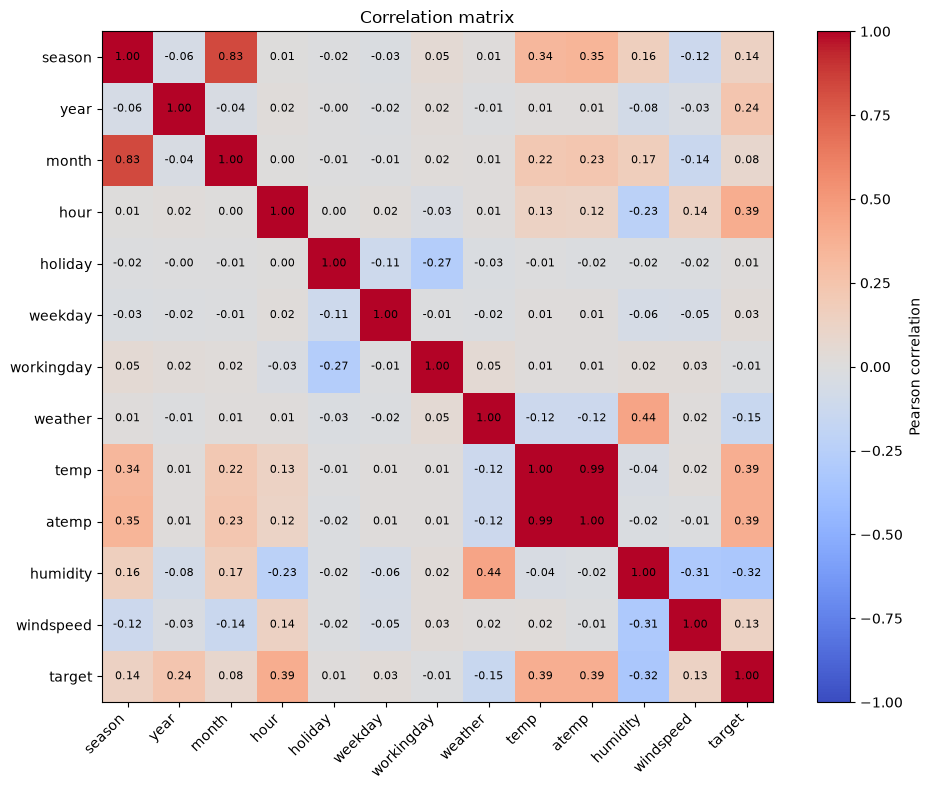

In [21]:
import matplotlib.pyplot as plt

corr = df.corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)

# Write the value in each cell
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, label="Pearson correlation")
ax.set_title("Correlation matrix")
plt.tight_layout()
plt.show()

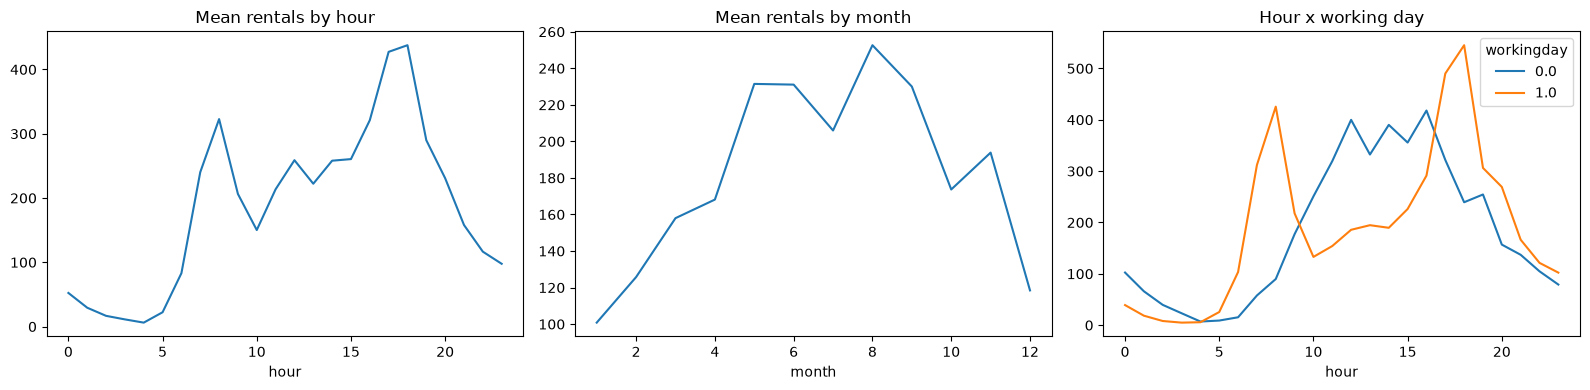

In [20]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
df.groupby("hour")["target"].mean().plot(ax=axes[0], title="Mean rentals by hour")
df.groupby("month")["target"].mean().plot(ax=axes[1], title="Mean rentals by month")
df.groupby(["workingday", "hour"])["target"].mean().unstack(0).plot(ax=axes[2], title="Hour x working day")
plt.tight_layout()
plt.show()